# AI-Assisted Complaint Triage for UAE Banks
### NLP Solution Design: prototype notebook (organic data version)

**What it does.** The system reads a customer's free-text complaint, masks personal data, predicts which product team should handle it, and sends low-confidence cases to a human reviewer instead of routing them automatically. It supports first-line complaint handling of the kind the CBUAE Consumer Protection Standards require: acknowledgement within 2 business days, a final response within 30 business days, and regular reporting of complaint volumes and types to senior management.

**Data.** Real complaint narratives written by members of the public about their own problems with financial institutions, published in the US CFPB Consumer Complaint Database with the consumer's opt-in consent after personal-data scrubbing. On 14 August 2026 the CFPB stopped publishing narratives in the live database and moved every previously published narrative to its FOIA Reading Room archive. This notebook downloads from that archive. The earlier pilot used BANKING77, a curated benchmark; this version replaces it with organic data.

**How to run.** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all. On a T4 a full run takes roughly 30–45 minutes, mostly downloading, embedding and fine-tuning. Without a GPU, fine-tuning is skipped automatically.

| Notebook section | Report section it feeds |
|---|---|
| 1–2 Data acquisition and labels | Input data description |
| 3–4 Pre-processing, temporal split, EDA | Data considerations and pre-processing |
| 5–8 Models and model selection | Pipeline/architecture, model selection and tuning |
| 9–10 Human-review threshold, test results | Evaluation, expected output |
| 11 Responsible-AI checks | Ethical considerations and mitigation |
| 12–13 Demo and saved artifacts | Prototype/demo, tool stack, repository |

## 0. Setup
Colab already includes pandas, scikit-learn, PyTorch and Transformers. The next cell adds the two libraries it lacks.

In [1]:
%pip install -q sentence-transformers gradio pyarrow

In [2]:
# =====================================================================
# 0. CONFIGURATION: every setting the experiment depends on lives here
# =====================================================================
import os, re, json, random, hashlib, shutil, unicodedata, zipfile, platform, importlib.metadata
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Storage --------------------------------------------------------
# Colab deletes local files when the runtime resets. Set this to True to
# keep downloads, embeddings and results in Google Drive instead.
USE_GOOGLE_DRIVE = True
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/uae_complaint_triage")
else:
    BASE_DIR = Path("uae_complaint_triage")

RAW_DIR = BASE_DIR / "data" / "raw"        # downloaded archive files (never commit these to GitHub)
CACHE_DIR = BASE_DIR / "data" / "cache"    # parsed tables and embeddings, so re-runs are fast

# ---- Data source: CFPB narratives archive in the FOIA Reading Room ----
ARCHIVE_URL = "https://files.consumerfinance.gov/f/documents/"
ARCHIVE_FILES = [
    "CCDB_Export_15_January_2026_through_February_2026.zip",
    "CCDB_Export_16_March_2026.zip",
    "CCDB_Export_17_April_2026.zip",
    "CCDB_Export_18_May_2026.zip",
    "CCDB_Export_19_June_2026.zip",
    "CCDB_Export_20_July_2026.zip",
    "CCDB_Export_21_August_2026.zip",
]

# Temporal split: train on the past, tune on the next month, test on the latest months.
VAL_START = "2026-05-01"
TEST_START = "2026-06-01"

# ---- What the model predicts ------------------------------------------
# "product": route each complaint to a product team (main experiment)
# "issue":   fine-grained issue within one team (optional second experiment)
TARGET = "product"
ISSUE_SCOPE = "Bank account"       # used only when TARGET == "issue"

# ---- Sample sizes -----------------------------------------------------
TRAIN_MAX_PER_CLASS = 4000   # cap per class so the largest class does not dominate training
VAL_SIZE = 8000              # random sample of the validation month (real class mix)
TEST_SIZE = 12000            # random sample of the test months (real class mix)
MIN_WORDS = 10               # narratives shorter than this are dropped
MIN_TRAIN_PER_CLASS = 300    # classes with fewer training examples are dropped

# ---- Models -----------------------------------------------------------
TFIDF_C_GRID = [0.5, 2.0, 8.0, 32.0]
EMBEDDING_MODELS = [
    # name, number of tokens the encoder reads, text prefix the model expects
    {"name": "sentence-transformers/all-MiniLM-L6-v2", "max_seq_length": 256, "prefix": ""},  # pilot encoder
    {"name": "BAAI/bge-small-en-v1.5", "max_seq_length": 512, "prefix": ""},
    # Arabic/English option for a UAE deployment (slower):
    # {"name": "intfloat/multilingual-e5-small", "max_seq_length": 512, "prefix": "query: "},
]
EMB_C_GRID = [1.0, 10.0, 100.0]

RUN_FINETUNE = DEVICE == "cuda"    # fine-tuning on a CPU would take hours
FINETUNE_MODEL = "distilroberta-base"
FT_MAX_LEN = 256                   # tokens per complaint: first half + last half of long texts
FT_EPOCHS = 2
FT_BATCH_SIZE = 32
FT_LR = 5e-5

PRIOR_ALPHAS = [0.0, 0.5, 1.0]     # strength of the class-mix correction, chosen on validation

# ---- Human-review rule ------------------------------------------------
TARGET_ACCURACY = 0.95   # required accuracy on complaints that are routed automatically
MIN_COVERAGE = 0.50      # at least this share of complaints should be routed automatically
CONFIDENCE_FLOOR = 0.50  # never auto-route unless the top team gets at least half the probability

LAUNCH_DEMO = True       # start the Gradio demo in section 12

OUTPUT = BASE_DIR / f"results_{TARGET}"
FIG_DIR = OUTPUT / "figures"
for folder in (RAW_DIR, CACHE_DIR, OUTPUT, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

if DEVICE == "cpu":
    print("No GPU found: fine-tuning is skipped and only the first embedding model is used.")
    print("For the full experiment use Runtime -> Change runtime type -> T4 GPU.\n")
    EMBEDDING_MODELS = EMBEDDING_MODELS[:1]


def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return "not installed"


print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("Python", platform.python_version())
for name in ["numpy", "pandas", "scikit-learn", "torch", "transformers", "sentence-transformers", "gradio"]:
    print(f"  {name:22s} {package_version(name)}")

# ---- Chart style used for every figure in the report -------------------
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.edgecolor": GREY,
})


def save_figure(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print("saved", path)

Mounted at /content/drive
Device: cuda Tesla T4
Python 3.13.16
  numpy                  2.1.3
  pandas                 2.2.3
  scikit-learn           1.6.1
  torch                  2.11.0+cu130
  transformers           5.20.2
  sentence-transformers  5.7.0
  gradio                 6.30.0


## 1. Data acquisition

**Why this dataset counts as organic.** Each narrative was written by a real consumer describing their own problem with a real institution, in their own words, when they filed the complaint. The product and issue labels were chosen by the consumer on the complaint form, not added later by annotators. Nothing was paraphrased or generated by researchers.

**Provenance and consent.** The CFPB published a narrative only when the consumer opted in, and only after a three-step scrubbing process: software, then a trained reviewer, then quality assurance. Personal details are replaced with `XXXX` and dollar amounts are rounded. Narratives that could not be scrubbed were withheld.

**Caveats to state in the report.** The CFPB describes the database as not a statistical sample of consumer experiences, and the allegations are not verified. The data is US-based and English-only. Raw files are not redistributed in the repository; the code downloads them from the source.

In [3]:
import requests


def download(file_name):
    """Download one archive file once; later runs reuse the local copy."""
    dest = RAW_DIR / file_name
    if dest.exists() and zipfile.is_zipfile(dest):
        print(f"  using local copy: {file_name}")
        return dest
    tmp = dest.with_name(dest.name + ".part")
    with requests.get(ARCHIVE_URL + file_name, stream=True, timeout=120,
                      headers={"User-Agent": "Mozilla/5.0 (student research project)"}) as response:
        response.raise_for_status()
        with open(tmp, "wb") as f:
            for block in response.iter_content(chunk_size=1 << 20):
                f.write(block)
    tmp.replace(dest)
    if not zipfile.is_zipfile(dest):
        dest.unlink()
        raise ValueError(f"{file_name} is not a valid zip file")
    print(f"  downloaded {file_name} ({dest.stat().st_size / 1e6:,.0f} MB)")
    return dest


archive_paths = []
for file_name in ARCHIVE_FILES:
    try:
        archive_paths.append(download(file_name))
    except Exception as error:
        print(f"  FAILED {file_name}: {error}")

if not archive_paths:
    raise RuntimeError(
        "No archive file could be downloaded. Download the zips manually from\n"
        "https://www.consumerfinance.gov/foia-requests/foia-electronic-reading-room/"
        "cfpb-consumer-complaint-database-narratives-archive/\n"
        f"and upload them to {RAW_DIR.resolve()}"
    )

  using local copy: CCDB_Export_15_January_2026_through_February_2026.zip
  using local copy: CCDB_Export_16_March_2026.zip
  using local copy: CCDB_Export_17_April_2026.zip
  using local copy: CCDB_Export_18_May_2026.zip
  using local copy: CCDB_Export_19_June_2026.zip
  using local copy: CCDB_Export_20_July_2026.zip
  using local copy: CCDB_Export_21_August_2026.zip


In [4]:
# Archive column headers -> short names. Headers are matched after lower-casing and
# replacing punctuation, so "Sub-product" and "sub_product" are treated the same.
COLUMNS = {
    "complaint_id": "complaint_id",
    "date_received": "date",
    "product": "product_raw",
    "sub_product": "sub_product",
    "issue": "issue",
    "sub_issue": "sub_issue",
    "consumer_complaint_narrative": "narrative",
    "complaint_what_happened": "narrative",   # name used by the CFPB API
    "tags": "tags",
    "state": "state",
    "company": "company",                     # kept for description only, never a model input
}
REQUIRED = {"complaint_id", "date", "product_raw", "issue", "narrative"}


def header_key(column):
    return re.sub(r"[^a-z0-9]+", "_", str(column).strip().lower()).strip("_")


def read_archive(zip_path, chunksize=100_000):
    """Read every CSV inside one archive zip, keeping only complaints that have a narrative."""
    frames = []
    with zipfile.ZipFile(zip_path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith(".csv")]
        if not members:
            raise ValueError(f"No CSV inside {zip_path.name}; contents: {zf.namelist()[:5]}")
        for member in members:
            with zf.open(member) as handle:
                reader = pd.read_csv(
                    handle, dtype=str, chunksize=chunksize,
                    usecols=lambda c: header_key(c) in COLUMNS,
                    encoding="utf-8", encoding_errors="replace", on_bad_lines="skip",
                )
                for chunk in reader:
                    chunk = chunk.rename(columns=lambda c: COLUMNS[header_key(c)])
                    missing = REQUIRED - set(chunk.columns)
                    if missing:
                        raise ValueError(f"{member} has no column(s) {missing}; found {list(chunk.columns)}")
                    frames.append(chunk.dropna(subset=["narrative", "product_raw", "date"]))
    return pd.concat(frames, ignore_index=True)


files_key = hashlib.md5("|".join(sorted(p.name for p in archive_paths)).encode()).hexdigest()[:10]
pool_cache = CACHE_DIR / f"parsed_archive_{files_key}.parquet"

if pool_cache.exists():
    raw = pd.read_parquet(pool_cache)
    print("Loaded parsed archive from cache:", pool_cache.name)
else:
    start = perf_counter()
    tables = []
    for path in archive_paths:
        table = read_archive(path)
        print(f"  {path.name}: {len(table):,} complaints with narratives")
        tables.append(table)
    raw = pd.concat(tables, ignore_index=True)
    raw.to_parquet(pool_cache, index=False)
    print(f"Parsed in {perf_counter() - start:.0f}s")

dates = pd.to_datetime(raw["date"], errors="coerce", format="ISO8601")
if dates.isna().mean() > 0.05:             # fall back if the archive uses another date format
    dates = pd.to_datetime(raw["date"], errors="coerce", format="mixed")
raw["date"] = dates
raw["product_raw"] = raw["product_raw"].str.strip()
raw["issue"] = raw["issue"].str.strip()
raw = raw.dropna(subset=["date"]).drop_duplicates("complaint_id").reset_index(drop=True)

for optional in ["sub_product", "sub_issue", "tags", "state", "company"]:
    if optional not in raw:
        raw[optional] = np.nan                # keeps later cells working if a column is absent

print(f"\n{len(raw):,} unique complaints with narratives, received "
      f"{raw['date'].min():%d %b %Y} to {raw['date'].max():%d %b %Y}, "
      f"about {raw['company'].nunique():,} companies")

  CCDB_Export_15_January_2026_through_February_2026.zip: 34,351 complaints with narratives
  CCDB_Export_16_March_2026.zip: 21,640 complaints with narratives
  CCDB_Export_17_April_2026.zip: 21,052 complaints with narratives
  CCDB_Export_18_May_2026.zip: 17,528 complaints with narratives
  CCDB_Export_19_June_2026.zip: 16,820 complaints with narratives
  CCDB_Export_20_July_2026.zip: 10,002 complaints with narratives
  CCDB_Export_21_August_2026.zip: 1 complaints with narratives
Parsed in 59s

121,394 unique complaints with narratives, received 01 Jan 2026 to 11 Aug 2026, about 2,362 companies


## 2. Labels: from CFPB products to bank routing teams
The consumer picks a product when filing a complaint. The CFPB has renamed products over the years, so older and newer names are mapped to one routing team each. That team is the label the model predicts.

Two products are excluded. **Student loan** is mostly a US federal programme with no UAE retail-banking equivalent. **Other financial service** is too vague to route. The cell below prints any product the map does not cover, so nothing is silently lost.

In [5]:
# CFPB product names (current and older) -> team that would handle the complaint in a bank
ROUTE_MAP = {
    "Checking or savings account": "Bank account",
    "Bank account or service": "Bank account",
    "Credit card": "Cards",
    "Prepaid card": "Cards",
    "Credit card or prepaid card": "Cards",
    "Credit reporting or other personal consumer reports": "Credit reporting",
    "Credit reporting, credit repair services, or other personal consumer reports": "Credit reporting",
    "Credit reporting": "Credit reporting",
    "Debt collection": "Debt collection",
    "Debt or credit management": "Debt collection",   # debt settlement/relief services: collections & recoveries team
    "Mortgage": "Mortgage",
    "Money transfer, virtual currency, or money service": "Money transfer",
    "Money transfers": "Money transfer",
    "Virtual currency": "Money transfer",
    "Payday loan, title loan, personal loan, or advance loan": "Personal loan",
    "Payday loan, title loan, or personal loan": "Personal loan",
    "Payday loan": "Personal loan",
    "Vehicle loan or lease": "Vehicle loan",
    "Consumer Loan": "Vehicle loan",
}
EXCLUDED_PRODUCTS = {"Student loan", "Other financial service"}

print("Products in the downloaded data:")
display(raw["product_raw"].value_counts().rename("complaints").to_frame())

unmapped = raw.loc[~raw["product_raw"].isin(set(ROUTE_MAP) | EXCLUDED_PRODUCTS), "product_raw"].value_counts()
if len(unmapped):
    print("WARNING: these products have no route and are dropped. Add them to ROUTE_MAP if they matter:")
    display(unmapped.rename("complaints").to_frame())

data = raw[raw["product_raw"].isin(ROUTE_MAP)].copy()
data["route"] = data["product_raw"].map(ROUTE_MAP)
del raw

if TARGET == "product":
    data["label"] = data["route"]
    LABEL_NAME = "team"
elif TARGET == "issue":
    data = data[data["route"] == ISSUE_SCOPE].copy()
    data["label"] = data["issue"]
    LABEL_NAME = "issue"
else:
    raise ValueError("TARGET must be 'product' or 'issue'")

data = data.dropna(subset=["label"]).reset_index(drop=True)
print(f"\n{len(data):,} complaints across {data['label'].nunique()} {LABEL_NAME} labels")
display(data["label"].value_counts().rename("complaints").to_frame())

Products in the downloaded data:


,complaints
product_raw,
Debt collection,40205
Checking or savings account,21335
Credit card,20435
"Money transfer, virtual currency, or money service",9807
Mortgage,7772
Vehicle loan or lease,5921
Credit reporting or other personal consumer reports,4945
"Payday loan, title loan, personal loan, or advance loan",4356
Student loan,4055



117,339 complaints across 8 team labels


,complaints
label,
Debt collection,41306
Cards,21897
Bank account,21335
Money transfer,9807
Mortgage,7772
Vehicle loan,5921
Credit reporting,4945
Personal loan,4356


## 3. Pre-processing

| Step | What it does | Why |
|---|---|---|
| Unicode normalisation | NFKC, control characters removed | Consistent characters from web forms and mobile keyboards |
| Privacy masking | CFPB redactions (`XXXX`, `XX/XX/2026`) → `[REDACTED]`; amounts → `[AMOUNT]`; emails, URLs, phone numbers, IBANs, Emirates ID numbers, card/account numbers and dates → placeholders | The archive is already scrubbed, but the same function runs on live complaints at deployment, so the model only ever sees masked text (privacy by design, and the same input format in training and use) |
| Placeholder and whitespace collapse | `[REDACTED] [REDACTED]` → `[REDACTED]` | Redaction runs carry no meaning |
| Short-text filter | Drop narratives under `MIN_WORDS` words | Too little content to route |
| Duplicate removal | Exact duplicates after normalisation are removed, keeping the earliest | Template letters repeat across complaints and would otherwise leak from training into test |

**Deliberately not done.** Lower-casing is left to TF-IDF, which does it internally; the transformer models use case. Stop words are kept and no stemming is applied, because negations such as "never received" carry meaning and contextual models need whole sentences. Long narratives are handled per model: TF-IDF reads the whole text, sentence encoders read the first 256–512 tokens, and the fine-tuned model reads the first and last 127 tokens (head+tail truncation, Sun et al., 2019).

In [6]:
# Applied in this order. The first two handle the CFPB's own redaction format.
PLACEHOLDER_PATTERNS = [
    (re.compile(r"\{\$\s?[\d,]+(?:\.\d+)?\}"), "[AMOUNT]"),                                # {$1,200.00}
    (re.compile(r"\bX{2,}(?:[/\-]X{2,})*(?:[/\-](?:\d{2,4}|X{2,4}))?\b"), "[REDACTED]"),   # XXXX, XX/XX/2026
    (re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"), "[EMAIL]"),
    (re.compile(r"(?:https?://|www\.)\S+", re.I), "[URL]"),
    (re.compile(r"\b[A-Z]{2}\d{2}(?:\s?[A-Z0-9]{4}){3,7}(?:\s?[A-Z0-9]{1,3})?\b"), "[IBAN]"),
    (re.compile(r"\b784[-\s]?\d{4}[-\s]?\d{7}[-\s]?\d\b"), "[EMIRATES_ID]"),
    (re.compile(r"(?<!\w)(?:\+|00)\d{1,3}[\s-]?\d{1,4}[\s-]?\d{3}[\s-]?\d{3,4}(?!\w)"), "[PHONE]"),
    (re.compile(r"(?<!\w)\(?\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}(?!\w)"), "[PHONE]"),
    (re.compile(r"\b(?:\d[ -]?){12,18}\d\b"), "[CARD_OR_ACCOUNT]"),
    (re.compile(r"\b\d{1,2}[/.-]\d{1,2}[/.-]\d{2,4}\b"), "[DATE]"),
    (re.compile(r"(?:\$|\b(?:USD|AED|Dhs?)\.?)\s?\d[\d,]*(?:\.\d+)?", re.I), "[AMOUNT]"),
    (re.compile(r"\b\d[\d,]*(?:\.\d+)?\s?(?:AED|USD|dirhams?|dollars?)\b", re.I), "[AMOUNT]"),
    (re.compile(r"\b\d{7,}\b"), "[NUMBER]"),
]
REPEATED_PLACEHOLDER = re.compile(r"(\[[A-Z_]+\])(?:[\s,.;:/-]*\1)+")
CONTROL_CHARS = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")
WHITESPACE = re.compile(r"\s+")


def clean_text(text):
    """Normalise and mask one complaint. Used for training data and for live input."""
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = CONTROL_CHARS.sub(" ", text)
    for pattern, placeholder in PLACEHOLDER_PATTERNS:
        text = pattern.sub(placeholder, text)
    text = REPEATED_PLACEHOLDER.sub(r"\1", text)
    return WHITESPACE.sub(" ", text).strip()


def dedup_key(text):
    """Fingerprint that ignores case, punctuation and numbers, for finding duplicate letters."""
    return hashlib.md5(re.sub(r"[^a-z]+", " ", text.lower()).strip().encode()).hexdigest()


# Masking check on an invented example (all details are fake)
example = ("My card 4111 1111 1111 1111 was charged {$250.00} on XX/XX/2026 by XXXX XXXX. "
           "Call me on +971 50 123 4567 or email jane.doe@example.com. "
           "IBAN AE07 0331 2345 6789 0123 456, Emirates ID 784-1990-1234567-1.")
print("before:", example)
print("after: ", clean_text(example))

before: My card 4111 1111 1111 1111 was charged {$250.00} on XX/XX/2026 by XXXX XXXX. Call me on +971 50 123 4567 or email jane.doe@example.com. IBAN AE07 0331 2345 6789 0123 456, Emirates ID 784-1990-1234567-1.
after:  My card [CARD_OR_ACCOUNT] was charged [AMOUNT] on [REDACTED] by [REDACTED]. Call me on [PHONE] or email [EMAIL]. IBAN [IBAN], Emirates ID [EMIRATES_ID].


In [7]:
start = perf_counter()
data["text"] = [clean_text(t) for t in data["narrative"]]
data["n_words"] = data["text"].str.count(" ") + 1
data["dedup_key"] = [dedup_key(t) for t in data["text"]]
print(f"Cleaned {len(data):,} narratives in {perf_counter() - start:.0f}s")

print("\nBefore/after examples (first 400 characters):")
for _, row in data.sample(2, random_state=SEED).iterrows():
    print("-" * 100)
    print("RAW:  ", row["narrative"][:400])
    print("CLEAN:", row["text"][:400])

n_start = len(data)
data = data[data["n_words"] >= MIN_WORDS]
n_after_length = len(data)

data = data.sort_values(["date", "complaint_id"])
is_duplicate = data.duplicated("dedup_key", keep="first")
duplicates_by_label = (
    pd.DataFrame({"complaints": data["label"].value_counts(),
                  "duplicates_removed": data.loc[is_duplicate, "label"].value_counts()})
    .fillna(0).astype(int)
    .assign(share_removed=lambda d: (d["duplicates_removed"] / d["complaints"]).round(3))
    .sort_values("complaints", ascending=False)
)
data = data[~is_duplicate].drop(columns=["narrative"]).reset_index(drop=True)

print(f"\nStarted with {n_start:,}; removed {n_start - n_after_length:,} under {MIN_WORDS} words "
      f"and {int(is_duplicate.sum()):,} duplicates; {len(data):,} remain.")
display(duplicates_by_label)
duplicates_by_label.to_csv(OUTPUT / "duplicates_by_label.csv")

Cleaned 117,339 narratives in 92s

Before/after examples (first 400 characters):
----------------------------------------------------------------------------------------------------
RAW:   TRUEACCORD C is falsely reporting on my credit. I have never had any accounts with them. Per my research TRUEACCORD C is a debt collector. They are falsely reporting on my credit!! Account number is XXXX is falsely reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of investigation consumer report ; you are in violation.
CLEAN: TRUEACCORD C is falsely reporting on my credit. I have never had any accounts with them. Per my research TRUEACCORD C is a debt collector. They are falsely reporting on my credit!! Account number is [REDACTED] is falsely reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of investigation consumer report ; you are in violation.
--------------------------------------

,complaints,duplicates_removed,share_removed
label,,,
Debt collection,41178,10136,0.246
Cards,21819,218,0.010
Bank account,21305,38,0.002
Money transfer,9801,63,0.006
Mortgage,7769,3,0.000
Vehicle loan,5912,38,0.006
Credit reporting,4889,2328,0.476
Personal loan,4347,14,0.003


## 4. Temporal split, sampling and exploratory analysis
The data is split by **date received**, not at random: the model is trained on earlier months, tuned on the next month, and tested on the latest months. This mirrors deployment, where a model trained on past complaints meets future ones, and it exposes drift such as new scams or changes in product mix that a random split would hide.

The training set is capped per class so the largest class (usually credit reporting) does not dominate. Validation and test keep the real class mix, because the human-review rate and accuracy have to be measured on the traffic the bank would actually receive.

In [8]:
data["split"] = np.select(
    [data["date"] < pd.Timestamp(VAL_START), data["date"] < pd.Timestamp(TEST_START)],
    ["train", "val"], default="test",
)
counts = pd.crosstab(data["label"], data["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
for name in ["train", "val", "test"]:
    if counts[name].sum() == 0:
        raise RuntimeError(f"No complaints fall in the {name} period; check VAL_START/TEST_START "
                           f"against the date range printed in section 1.")

keep = counts.index[counts["train"] >= MIN_TRAIN_PER_CLASS]
dropped = counts.index.difference(keep)
if len(dropped):
    print(f"Dropped labels with fewer than {MIN_TRAIN_PER_CLASS} training complaints: {list(dropped)}")
data = data[data["label"].isin(keep)].reset_index(drop=True)

LABELS = sorted(keep)
K = len(LABELS)
LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}
LABEL_IDS = list(range(K))

# Real class mix in the training period (before capping). Used to correct predictions later.
natural_prior = (data.loc[data["split"] == "train", "label"]
                 .value_counts(normalize=True).reindex(LABELS).to_numpy())

shuffled = data.sample(frac=1.0, random_state=SEED)
train_df = shuffled[shuffled["split"] == "train"].groupby("label").head(TRAIN_MAX_PER_CLASS).reset_index(drop=True)
val_df = shuffled[shuffled["split"] == "val"].head(VAL_SIZE).reset_index(drop=True)
test_df = shuffled[shuffled["split"] == "test"].head(TEST_SIZE).reset_index(drop=True)
del shuffled

frames = {"train": train_df, "val": val_df, "test": test_df}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not set(frames[a]["complaint_id"]) & set(frames[b]["complaint_id"]), f"{a}/{b} share complaints"
    assert not set(frames[a]["dedup_key"]) & set(frames[b]["dedup_key"]), f"{a}/{b} share duplicate texts"
print("Leakage checks passed: no complaint or duplicate text appears in two splits.")

y_train, y_val, y_test = (frames[s]["label"].map(LABEL_TO_ID).to_numpy() for s in ["train", "val", "test"])
X_train, X_val, X_test = (frames[s]["text"].tolist() for s in ["train", "val", "test"])
train_prior = np.bincount(y_train, minlength=K) / len(y_train)
PRIOR_RATIO = natural_prior / train_prior

split_table = pd.DataFrame({
    "train_period_all": counts.loc[LABELS, "train"],
    "train_period_share": natural_prior.round(3),
    "train_used": pd.Series(y_train).value_counts().reindex(range(K), fill_value=0).set_axis(LABELS),
    "val": pd.Series(y_val).value_counts().reindex(range(K), fill_value=0).set_axis(LABELS),
    "test": pd.Series(y_test).value_counts().reindex(range(K), fill_value=0).set_axis(LABELS),
})
split_table.loc["Total"] = split_table.sum().round(3)
display(split_table)
split_table.to_csv(OUTPUT / "split_table.csv")

pd.concat([f[["complaint_id"]].assign(split=s) for s, f in frames.items()]).to_csv(
    OUTPUT / "split_complaint_ids.csv", index=False)   # lets anyone rebuild the exact splits

Leakage checks passed: no complaint or duplicate text appears in two splits.


,train_period_all,train_period_share,train_used,val,test
Bank account,12948.0,0.196,4000.0,1637.0,2735.0
Cards,13479.0,0.204,4000.0,1676.0,2559.0
Credit reporting,1589.0,0.024,1589.0,186.0,330.0
Debt collection,20598.0,0.312,4000.0,2316.0,3158.0
Money transfer,6206.0,0.094,4000.0,764.0,1081.0
Mortgage,4755.0,0.072,4000.0,597.0,966.0
Personal loan,2644.0,0.040,2644.0,353.0,520.0
Vehicle loan,3724.0,0.056,3724.0,471.0,651.0
Total,65943.0,0.998,27957.0,8000.0,12000.0


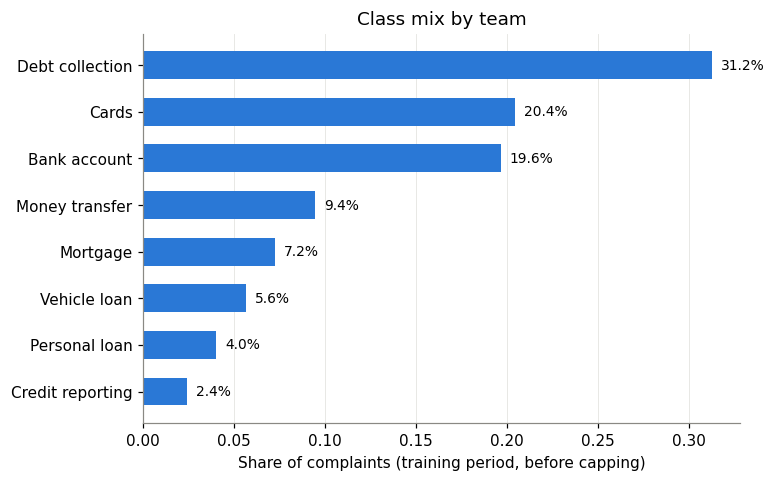

saved /content/drive/MyDrive/uae_complaint_triage/results_product/figures/fig1_class_mix.png


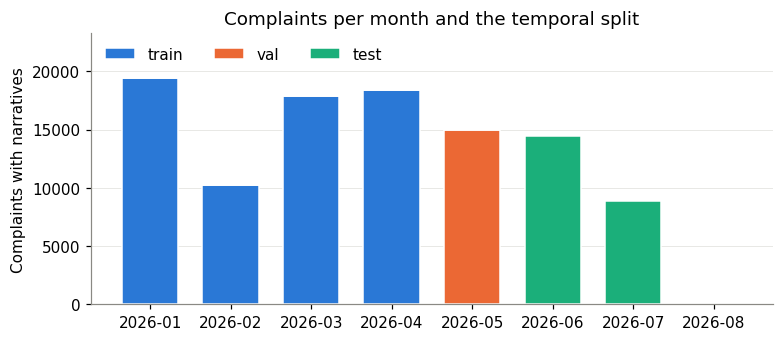

saved /content/drive/MyDrive/uae_complaint_triage/results_product/figures/fig2_monthly_split.png


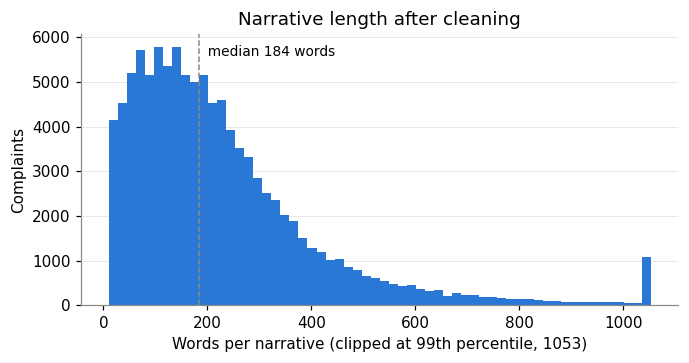

saved /content/drive/MyDrive/uae_complaint_triage/results_product/figures/fig3_length.png


,count,mean,50%,90%,max
label,,,,,
Bank account,21267.0,236.0,188.0,453.0,5188.0
Cards,21601.0,249.0,204.0,466.0,4889.0
Credit reporting,2561.0,194.0,125.0,384.0,5074.0
Debt collection,31042.0,199.0,154.0,390.0,4625.0
Money transfer,9738.0,228.0,184.0,429.0,4226.0
Mortgage,7766.0,321.0,243.0,616.0,4655.0
Personal loan,4333.0,222.0,183.0,426.0,1997.0
Vehicle loan,5874.0,257.0,208.0,479.0,4924.0


Tags (used later for the fairness check):


,share
tags,
None,0.8289
Servicemember,0.0978
Older American,0.0588
"Older American, Servicemember",0.0145


In [9]:
# Figure 1: real class mix in the training period
share = pd.Series(natural_prior, index=LABELS).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.45 * K + 1))
ax.barh(share.index, share.values, color=BLUE, height=0.6)
for y, v in enumerate(share.values):
    ax.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=9)
ax.set_xlabel("Share of complaints (training period, before capping)")
ax.set_title(f"Class mix by {LABEL_NAME}")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig1_class_mix")

# Figure 2: complaints per month and the temporal split
monthly = data.groupby([data["date"].dt.to_period("M"), "split"]).size().unstack(fill_value=0)
monthly = monthly.reindex(columns=["train", "val", "test"], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(monthly))
bottom = np.zeros(len(monthly))
for split, colour in [("train", BLUE), ("val", ORANGE), ("test", AQUA)]:
    ax.bar(x, monthly[split].values, bottom=bottom, color=colour, width=0.7, label=split, edgecolor="white", linewidth=1)
    bottom += monthly[split].values
ax.set_xticks(x, [str(p) for p in monthly.index], rotation=0)
ax.set_ylabel("Complaints with narratives")
ax.set_title("Complaints per month and the temporal split")
ax.set_ylim(0, monthly.sum(axis=1).max() * 1.2)
ax.legend(frameon=False, ncols=3, loc="upper left")
ax.grid(axis="x", visible=False)
save_figure(fig, "fig2_monthly_split")

# Figure 3: narrative length
cap = data["n_words"].quantile(0.99)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(data["n_words"].clip(upper=cap), bins=60, color=BLUE)
median_words = data["n_words"].median()
ax.axvline(median_words, color=GREY, linestyle="--", linewidth=1)
ax.text(median_words, ax.get_ylim()[1] * 0.92, f"  median {median_words:.0f} words", fontsize=9)
ax.set_xlabel(f"Words per narrative (clipped at 99th percentile, {cap:.0f})")
ax.set_ylabel("Complaints")
ax.set_title("Narrative length after cleaning")
ax.grid(axis="x", visible=False)
save_figure(fig, "fig3_length")

length_table = data.groupby("label")["n_words"].describe(percentiles=[0.5, 0.9])[["count", "mean", "50%", "90%", "max"]].round(0)
display(length_table)

tags_table = data["tags"].fillna("None").value_counts(normalize=True).round(4).rename("share").to_frame()
print("Tags (used later for the fairness check):")
display(tags_table)

## 5. Evaluation tools and the TF-IDF baseline
Every model outputs class probabilities, and every model is judged the same way on the validation month.

- **Primary metric: macro-F1.** It gives each team equal weight, so a model cannot score well by getting only the largest class right. Accuracy and weighted F1 are reported alongside it.
- **Class-mix correction.** Training was capped per class, but real traffic is not balanced. Multiplying the probabilities by (real share ÷ training share)^α and renormalising corrects for this (Saerens et al., 2002). α = 0 means no correction and α = 1 means full correction. α is chosen on validation.

The baseline is TF-IDF over word unigrams and bigrams with sublinear term frequency, followed by logistic regression. The grid of C values is wider than in the pilot, whose best value sat at the edge of its grid.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix


def adjust_for_class_mix(probs, alpha):
    """Re-weight probabilities from the capped training mix towards the real class mix."""
    weighted = probs * PRIOR_RATIO ** alpha
    return weighted / weighted.sum(axis=1, keepdims=True)


def score(y_true, probs):
    pred = probs.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, labels=LABEL_IDS, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, pred, labels=LABEL_IDS, average="weighted", zero_division=0),
    }


experiments = []   # every configuration tried, scored on validation only
candidates = {}    # best configuration of each model family


def record(family, setting, val_probs, fit_seconds, predict_fn, test_fn, artifacts):
    """Score one configuration on validation at each correction strength; keep the family's best."""
    best = None
    for alpha in PRIOR_ALPHAS:
        row = {"family": family, "setting": setting, "prior_alpha": alpha,
               **score(y_val, adjust_for_class_mix(val_probs, alpha)), "fit_seconds": round(fit_seconds, 1)}
        experiments.append(row)
        if best is None or row["macro_f1"] > best["macro_f1"]:
            best = row
    print(f"{setting:45s} val macro-F1 {best['macro_f1']:.4f}  accuracy {best['accuracy']:.4f}  "
          f"(alpha={best['prior_alpha']})")
    if family not in candidates or best["macro_f1"] > candidates[family]["macro_f1"]:
        candidates[family] = {**best, "val_probs": val_probs, "predict_fn": predict_fn,
                              "test_fn": test_fn, "artifacts": artifacts}


start = perf_counter()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True,
                             max_features=200_000, strip_accents="unicode")
T_train = vectorizer.fit_transform(X_train)
T_val = vectorizer.transform(X_val)
vectorize_seconds = perf_counter() - start
print(f"TF-IDF vocabulary: {len(vectorizer.vocabulary_):,} terms ({vectorize_seconds:.0f}s)\n")

for C in TFIDF_C_GRID:
    start = perf_counter()
    clf = LogisticRegression(C=C, max_iter=3000, random_state=SEED).fit(T_train, y_train)
    seconds = perf_counter() - start + vectorize_seconds
    record("TF-IDF + LogReg", f"TF-IDF 1-2 grams, C={C}", clf.predict_proba(T_val), seconds,
           predict_fn=lambda texts, c=clf: c.predict_proba(vectorizer.transform(texts)),
           test_fn=lambda c=clf: c.predict_proba(vectorizer.transform(X_test)),
           artifacts={"kind": "tfidf", "vectorizer": vectorizer, "clf": clf})

TF-IDF vocabulary: 200,000 terms (15s)

TF-IDF 1-2 grams, C=0.5                       val macro-F1 0.7658  accuracy 0.8016  (alpha=0.0)
TF-IDF 1-2 grams, C=2.0                       val macro-F1 0.7845  accuracy 0.8199  (alpha=0.5)
TF-IDF 1-2 grams, C=8.0                       val macro-F1 0.7852  accuracy 0.8181  (alpha=0.5)
TF-IDF 1-2 grams, C=32.0                      val macro-F1 0.7792  accuracy 0.8143  (alpha=1.0)


## 6. Sentence embeddings + logistic regression
A pretrained sentence encoder turns each complaint into one dense vector, and logistic regression is trained on those vectors. MiniLM is the pilot's encoder. BGE-small is a stronger encoder of the same size that reads up to 512 tokens. Embeddings are cached to disk, so re-running the notebook does not recompute them.

In [11]:
from sentence_transformers import SentenceTransformer


def embedding_cache(model_name, split, ids):
    digest = hashlib.md5(("|".join(map(str, ids)) + model_name).encode()).hexdigest()[:10]
    return CACHE_DIR / f"emb_{re.sub(r'[^A-Za-z0-9]+', '_', model_name)}_{split}_{digest}.npy"


def embed(encoder, spec, texts, batch_size=64):
    return encoder.encode([spec["prefix"] + t for t in texts], batch_size=batch_size,
                          normalize_embeddings=True, convert_to_numpy=True,
                          show_progress_bar=False).astype(np.float32)


for spec in EMBEDDING_MODELS:
    short_name = spec["name"].split("/")[-1]
    encoder = SentenceTransformer(spec["name"], device=DEVICE)
    encoder.max_seq_length = spec["max_seq_length"]
    start = perf_counter()
    vectors = {}
    for split, frame in frames.items():
        path = embedding_cache(spec["name"], split, frame["complaint_id"])
        if path.exists():
            vectors[split] = np.load(path)
        else:
            vectors[split] = embed(encoder, spec, frame["text"].tolist())
            np.save(path, vectors[split])
    embed_seconds = perf_counter() - start
    print(f"\n{short_name}: {vectors['train'].shape[1]}-dimensional vectors ({embed_seconds:.0f}s)")

    for C in EMB_C_GRID:
        start = perf_counter()
        clf = LogisticRegression(C=C, max_iter=3000, random_state=SEED).fit(vectors["train"], y_train)
        seconds = perf_counter() - start
        record(f"{short_name} + LogReg", f"{short_name} embeddings, C={C}", clf.predict_proba(vectors["val"]),
               seconds,
               predict_fn=lambda texts, e=encoder, s=spec, c=clf: c.predict_proba(embed(e, s, texts)),
               test_fn=lambda v=vectors, c=clf: c.predict_proba(v["test"]),
               artifacts={"kind": "embeddings", "encoder": spec, "clf": clf})

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


bge-small-en-v1.5: 384-dimensional vectors (365s)
bge-small-en-v1.5 embeddings, C=1.0           val macro-F1 0.7644  accuracy 0.7999  (alpha=0.5)
bge-small-en-v1.5 embeddings, C=10.0          val macro-F1 0.7688  accuracy 0.8014  (alpha=0.5)
bge-small-en-v1.5 embeddings, C=100.0         val macro-F1 0.7623  accuracy 0.8027  (alpha=1.0)


## 7. Fine-tuned transformer (GPU only)
DistilRoBERTa is fine-tuned end-to-end on the routing task: every layer adapts to complaint language, not only the final classifier. Long complaints keep their first and last 127 tokens, because consumers usually state the product at the start and the request at the end. Training uses AdamW with linear warm-up and decay, mixed precision and gradient clipping. The epoch with the best validation macro-F1 is kept.

In [12]:
if RUN_FINETUNE:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()

    tokenizer = AutoTokenizer.from_pretrained(FINETUNE_MODEL)
    use_amp = DEVICE == "cuda"

    def encode_head_tail(texts, max_len=FT_MAX_LEN):
        """Token ids per text; texts longer than max_len keep their first and last tokens."""
        body = max_len - 2
        head, tail = body // 2, body - body // 2
        ids = tokenizer(list(texts), add_special_tokens=False)["input_ids"]
        return [[tokenizer.cls_token_id] + (x if len(x) <= body else x[:head] + x[-tail:])
                + [tokenizer.sep_token_id] for x in ids]

    def batches(ids, labels=None, batch_size=FT_BATCH_SIZE, shuffle=False, seed=SEED):
        if shuffle:
            order = np.random.default_rng(seed).permutation(len(ids))
        else:
            order = np.argsort([len(x) for x in ids])   # similar lengths together: faster inference
        for begin in range(0, len(order), batch_size):
            idx = order[begin:begin + batch_size]
            width = max(len(ids[i]) for i in idx)
            input_ids = torch.full((len(idx), width), tokenizer.pad_token_id, dtype=torch.long)
            mask = torch.zeros((len(idx), width), dtype=torch.long)
            for row, i in enumerate(idx):
                input_ids[row, :len(ids[i])] = torch.tensor(ids[i])
                mask[row, :len(ids[i])] = 1
            target = None if labels is None else torch.as_tensor(labels[idx], dtype=torch.long).to(DEVICE)
            yield idx, {"input_ids": input_ids.to(DEVICE), "attention_mask": mask.to(DEVICE)}, target

    @torch.no_grad()
    def ft_predict_proba(model, ids):
        model.eval()
        probs = np.zeros((len(ids), K), dtype=np.float32)
        for idx, batch, _ in batches(ids, batch_size=FT_BATCH_SIZE * 2):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(**batch).logits
            probs[idx] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
        return probs

    train_ids, val_ids, test_ids = encode_head_tail(X_train), encode_head_tail(X_val), encode_head_tail(X_test)
    ft_model = AutoModelForSequenceClassification.from_pretrained(
        FINETUNE_MODEL, num_labels=K, id2label=dict(enumerate(LABELS)), label2id=LABEL_TO_ID).to(DEVICE)

    no_decay = ("bias", "LayerNorm.weight", "layer_norm.weight")
    optimizer = torch.optim.AdamW([
        {"params": [p for n, p in ft_model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": 0.01},
        {"params": [p for n, p in ft_model.named_parameters() if any(k in n for k in no_decay)], "weight_decay": 0.0},
    ], lr=FT_LR)
    steps_per_epoch = int(np.ceil(len(train_ids) / FT_BATCH_SIZE))
    total_steps = FT_EPOCHS * steps_per_epoch
    warmup = max(1, int(0.06 * total_steps))
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: (step + 1) / warmup if step < warmup
        else max(0.0, (total_steps - step) / max(1, total_steps - warmup)))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_f1, best_state, start = -1.0, None, perf_counter()
    for epoch in range(1, FT_EPOCHS + 1):
        ft_model.train()
        running = 0.0
        for step, (_, batch, target) in enumerate(batches(train_ids, y_train, shuffle=True, seed=SEED + epoch), 1):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = ft_model(**batch).logits
            loss = torch.nn.functional.cross_entropy(logits.float(), target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
            if step % 200 == 0:
                print(f"  epoch {epoch} step {step}/{steps_per_epoch} loss {running / step:.4f}")
        epoch_f1 = score(y_val, ft_predict_proba(ft_model, val_ids))["macro_f1"]
        print(f"epoch {epoch}: training loss {running / steps_per_epoch:.4f}, validation macro-F1 {epoch_f1:.4f}")
        if epoch_f1 > best_f1:
            best_f1 = epoch_f1
            best_state = {k: v.detach().cpu().clone() for k, v in ft_model.state_dict().items()}
    ft_model.load_state_dict(best_state)
    ft_seconds = perf_counter() - start

    ft_dir = OUTPUT / "finetuned_model"
    ft_model.save_pretrained(ft_dir)
    tokenizer.save_pretrained(ft_dir)
    ft_short = FINETUNE_MODEL.split("/")[-1]
    record(f"Fine-tuned {ft_short}", f"{ft_short}, {FT_EPOCHS} epochs, head+tail {FT_MAX_LEN}",
           ft_predict_proba(ft_model, val_ids), ft_seconds,
           predict_fn=lambda texts: ft_predict_proba(ft_model, encode_head_tail(texts)),
           test_fn=lambda: ft_predict_proba(ft_model, test_ids),
           artifacts={"kind": "finetune", "path": str(ft_dir)})
else:
    print("Fine-tuning skipped (no GPU). Switch to a T4 GPU runtime to include it.")

config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

  epoch 1 step 200/874 loss 1.1950
  epoch 1 step 400/874 loss 0.9563
  epoch 1 step 600/874 loss 0.8567
  epoch 1 step 800/874 loss 0.7892
epoch 1: training loss 0.7744, validation macro-F1 0.7549
  epoch 2 step 200/874 loss 0.4887
  epoch 2 step 400/874 loss 0.4881
  epoch 2 step 600/874 loss 0.4859
  epoch 2 step 800/874 loss 0.4798
epoch 2: training loss 0.4781, validation macro-F1 0.7855


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

distilroberta-base, 2 epochs, head+tail 256   val macro-F1 0.7990  accuracy 0.8313  (alpha=1.0)


## 8. Model selection (validation only)
The winner is the family with the highest validation macro-F1. The test set has not been used yet.

Top configurations on validation:


,family,setting,prior_alpha,accuracy,macro_f1,weighted_f1,fit_seconds
32,Fine-tuned distilroberta-base,"distilroberta-base, 2 epochs, head+tail 256",1.0,0.8312,0.7990,0.8322,411.7
31,Fine-tuned distilroberta-base,"distilroberta-base, 2 epochs, head+tail 256",0.5,0.8270,0.7942,0.8296,411.7
30,Fine-tuned distilroberta-base,"distilroberta-base, 2 epochs, head+tail 256",0.0,0.8195,0.7855,0.8241,411.7
7,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=8.0",0.5,0.8181,0.7852,0.8189,75.4
4,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=2.0",0.5,0.8199,0.7845,0.8197,89.9
11,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=32.0",1.0,0.8142,0.7792,0.8138,79.3
10,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=32.0",0.5,0.8145,0.7780,0.8161,79.3
3,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=2.0",0.0,0.8109,0.7775,0.8145,89.9
6,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=8.0",0.0,0.8104,0.7760,0.8139,75.4
8,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=8.0",1.0,0.8132,0.7729,0.8113,75.4



Selected model: Fine-tuned distilroberta-base (distilroberta-base, 2 epochs, head+tail 256, alpha=1.0)


,model,best_setting,prior_alpha,val_accuracy,val_macro_f1,fit_seconds
0,Fine-tuned distilroberta-base,"distilroberta-base, 2 epochs, head+tail 256",1.0,0.8312,0.7990,411.7
1,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=8.0",0.5,0.8181,0.7852,75.4
2,bge-small-en-v1.5 + LogReg,"bge-small-en-v1.5 embeddings, C=10.0",0.5,0.8014,0.7688,16.1
3,all-MiniLM-L6-v2 + LogReg,"all-MiniLM-L6-v2 embeddings, C=10.0",0.5,0.7876,0.7496,17.0


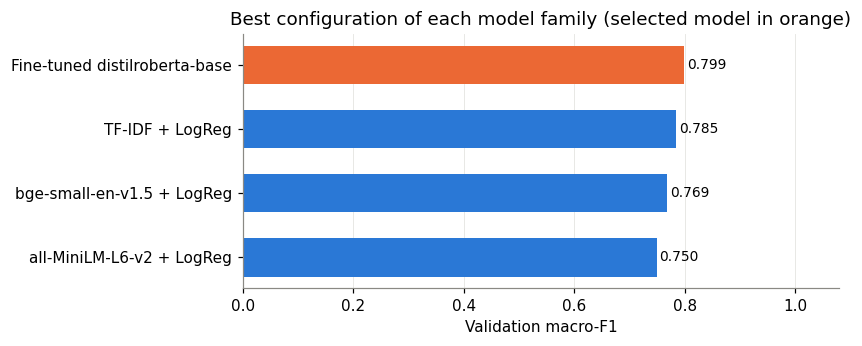

saved /content/drive/MyDrive/uae_complaint_triage/results_product/figures/fig4_model_comparison.png


In [13]:
results_df = pd.DataFrame(experiments).sort_values("macro_f1", ascending=False)
results_df.to_csv(OUTPUT / "validation_results.csv", index=False)
print("Top configurations on validation:")
display(results_df.head(12).round(4))

summary = pd.DataFrame([
    {"model": family, "best_setting": c["setting"], "prior_alpha": c["prior_alpha"],
     "val_accuracy": c["accuracy"], "val_macro_f1": c["macro_f1"], "fit_seconds": c["fit_seconds"]}
    for family, c in candidates.items()
]).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)

WINNER = summary.loc[0, "model"]
winner = candidates[WINNER]
print(f"\nSelected model: {WINNER} ({winner['setting']}, alpha={winner['prior_alpha']})")
display(summary.round(4))

ordered = summary.sort_values("val_macro_f1")
fig, ax = plt.subplots(figsize=(7, 0.5 * len(ordered) + 1))
ax.barh(ordered["model"], ordered["val_macro_f1"], color=[ORANGE if m == WINNER else BLUE for m in ordered["model"]], height=0.6)
for y, v in enumerate(ordered["val_macro_f1"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("Validation macro-F1")
ax.set_title("Best configuration of each model family (selected model in orange)")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig4_model_comparison")

## 9. Human-review threshold (selective prediction)
Complaints whose top probability falls below a threshold go to a person instead of being routed automatically. The threshold is chosen on validation as the lowest one that keeps the accuracy of auto-routed complaints at or above `TARGET_ACCURACY` while routing at least `MIN_COVERAGE` of them. It is never below `CONFIDENCE_FLOOR` (0.5), so text the model does not recognise, such as an off-topic question, goes to a person even when overall accuracy is high. Lower coverage means more work for reviewers; higher coverage means more misrouted complaints. The curve shows that trade-off.

Threshold 0.90: validation coverage 64.0%, accuracy on auto-routed complaints 95.1% (all complaints: 83.1%)


,threshold,coverage,accepted_accuracy
0,0.0,1.0000,0.8312
10,0.1,1.0000,0.8312
20,0.2,1.0000,0.8312
30,0.3,0.9984,0.8324
40,0.4,0.9848,0.8394
50,0.5,0.9510,0.8544
60,0.6,0.8951,0.8750
70,0.7,0.8335,0.8980
80,0.8,0.7589,0.9244
90,0.9,0.6400,0.9506


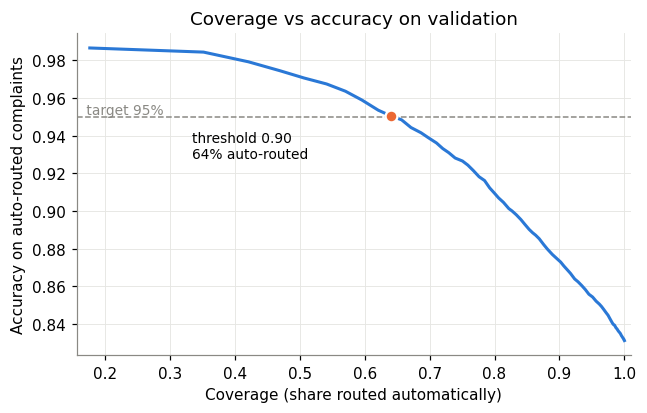

saved /content/drive/MyDrive/uae_complaint_triage/results_product/figures/fig5_coverage_accuracy.png


In [14]:
val_probs = adjust_for_class_mix(winner["val_probs"], winner["prior_alpha"])
val_conf = val_probs.max(axis=1)
val_correct = val_probs.argmax(axis=1) == y_val

curve = []
for threshold in np.round(np.linspace(0, 1, 101), 2):
    accepted = val_conf >= threshold
    curve.append({"threshold": threshold, "coverage": accepted.mean(),
                  "accepted_accuracy": val_correct[accepted].mean() if accepted.any() else np.nan})
curve = pd.DataFrame(curve)
curve.to_csv(OUTPUT / "threshold_curve_validation.csv", index=False)

allowed = curve[curve["threshold"] >= CONFIDENCE_FLOOR]
meets = allowed[(allowed["accepted_accuracy"] >= TARGET_ACCURACY) & (allowed["coverage"] >= MIN_COVERAGE)]
if len(meets):
    chosen = meets.sort_values("threshold").iloc[0]
else:
    fallback = allowed[allowed["coverage"] >= MIN_COVERAGE]
    if len(fallback) == 0:
        fallback = allowed.dropna()
    chosen = fallback.sort_values("accepted_accuracy", ascending=False).iloc[0]
    print(f"No threshold reaches {TARGET_ACCURACY:.0%} accuracy while auto-routing {MIN_COVERAGE:.0%}. "
          "Using the most accurate allowed threshold instead; report this trade-off.")
REVIEW_THRESHOLD = float(chosen["threshold"])
print(f"Threshold {REVIEW_THRESHOLD:.2f}: validation coverage {chosen['coverage']:.1%}, "
      f"accuracy on auto-routed complaints {chosen['accepted_accuracy']:.1%} "
      f"(all complaints: {val_correct.mean():.1%})")
display(curve.iloc[::10].round(4))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(curve["coverage"], curve["accepted_accuracy"], color=BLUE, linewidth=2)
ax.axhline(TARGET_ACCURACY, color=GREY, linestyle="--", linewidth=1)
ax.text(0.01, TARGET_ACCURACY, f" target {TARGET_ACCURACY:.0%}", fontsize=9, color=GREY, va="bottom",
        transform=ax.get_yaxis_transform())
ax.scatter([chosen["coverage"]], [chosen["accepted_accuracy"]], s=60, color=ORANGE, zorder=3,
           edgecolor="white", linewidth=1.5)
ax.annotate(f"threshold {REVIEW_THRESHOLD:.2f}\n{chosen['coverage']:.0%} auto-routed",
            (chosen["coverage"], chosen["accepted_accuracy"]), textcoords="offset points",
            xytext=(-130, -28), fontsize=9)
ax.set_xlim(max(0.0, curve["coverage"][curve["coverage"] > 0].min() - 0.02), 1.01)
ax.set_xlabel("Coverage (share routed automatically)")
ax.set_ylabel("Accuracy on auto-routed complaints")
ax.set_title("Coverage vs accuracy on validation")
save_figure(fig, "fig5_coverage_accuracy")

## 10. Test results (run once, after every choice above is fixed)
The test months were never used to choose a model, a setting or the threshold. The other families are also scored on test for the comparison table in the report, but they played no part in selection.

In [15]:
comparison = []
for family, c in candidates.items():
    c["test_probs"] = adjust_for_class_mix(c["test_fn"](), c["prior_alpha"])
    comparison.append({"model": family, **{f"test_{k}": v for k, v in score(y_test, c["test_probs"]).items()}})
comparison = summary.merge(pd.DataFrame(comparison), on="model")
comparison.to_csv(OUTPUT / "model_comparison.csv", index=False)
display(comparison.round(4))

test_probs = winner["test_probs"]
pred = test_probs.argmax(axis=1)
conf = test_probs.max(axis=1)
accepted = conf >= REVIEW_THRESHOLD
correct = pred == y_test

test_metrics = {
    "selected_model": WINNER,
    "setting": winner["setting"],
    "prior_alpha": winner["prior_alpha"],
    "test_complaints": int(len(y_test)),
    "test_period": f"{test_df['date'].min():%Y-%m-%d} to {test_df['date'].max():%Y-%m-%d}",
    **{k: float(v) for k, v in score(y_test, test_probs).items()},
    "review_threshold": REVIEW_THRESHOLD,
    "auto_routed_share": float(accepted.mean()),
    "human_review_share": float((~accepted).mean()),
    "accuracy_auto_routed": float(correct[accepted].mean()) if accepted.any() else None,
    "macro_f1_auto_routed": float(f1_score(y_test[accepted], pred[accepted], labels=LABEL_IDS,
                                           average="macro", zero_division=0)) if accepted.any() else None,
}
print(json.dumps(test_metrics, indent=2))
with open(OUTPUT / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

report_df = pd.DataFrame(classification_report(y_test, pred, labels=LABEL_IDS, target_names=LABELS,
                                               output_dict=True, zero_division=0)).T
display(report_df.round(3))
report_df.to_csv(OUTPUT / "test_classification_report.csv")

,model,best_setting,prior_alpha,val_accuracy,val_macro_f1,fit_seconds,test_accuracy,test_macro_f1,test_weighted_f1
0,Fine-tuned distilroberta-base,"distilroberta-base, 2 epochs, head+tail 256",1.0,0.8312,0.7990,411.7,0.8222,0.7941,0.8237
1,TF-IDF + LogReg,"TF-IDF 1-2 grams, C=8.0",0.5,0.8181,0.7852,75.4,0.8130,0.7809,0.8145
2,bge-small-en-v1.5 + LogReg,"bge-small-en-v1.5 embeddings, C=10.0",0.5,0.8014,0.7688,16.1,0.7922,0.7600,0.7942
3,all-MiniLM-L6-v2 + LogReg,"all-MiniLM-L6-v2 embeddings, C=10.0",0.5,0.7876,0.7496,17.0,0.7832,0.7449,0.7851


{
  "selected_model": "Fine-tuned distilroberta-base",
  "setting": "distilroberta-base, 2 epochs, head+tail 256",
  "prior_alpha": 1.0,
  "test_complaints": 12000,
  "test_period": "2026-06-01 to 2026-08-11",
  "accuracy": 0.82225,
  "macro_f1": 0.7940828106603215,
  "weighted_f1": 0.8237255524399201,
  "review_threshold": 0.9,
  "auto_routed_share": 0.6326666666666667,
  "human_review_share": 0.36733333333333335,
  "accuracy_auto_routed": 0.9475763962065332,
  "macro_f1_auto_routed": 0.9175280674391846
}


,precision,recall,f1-score,support
Bank account,0.807,0.791,0.799,2735.000
Cards,0.841,0.810,0.825,2559.000
Credit reporting,0.619,0.779,0.690,330.000
Debt collection,0.911,0.863,0.887,3158.000
Money transfer,0.666,0.740,0.701,1081.000
Mortgage,0.920,0.955,0.938,966.000
Personal loan,0.654,0.694,0.674,520.000
Vehicle loan,0.814,0.868,0.840,651.000
accuracy,0.822,0.822,0.822,0.822
macro avg,0.779,0.813,0.794,12000.000


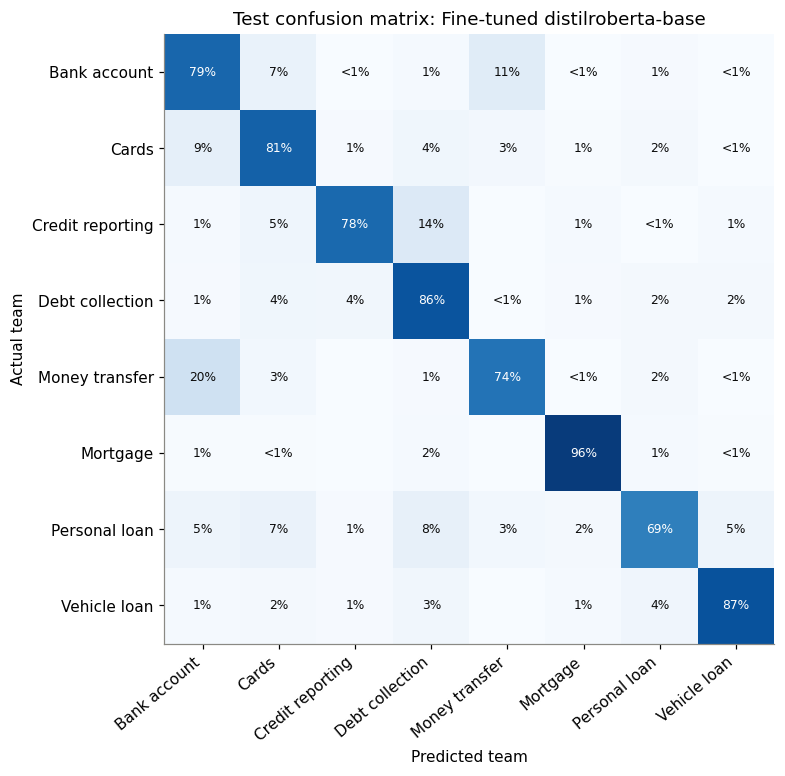

saved /content/drive/MyDrive/uae_complaint_triage/results_product/figures/fig6_confusion_matrix.png
Most frequent confusions:


count
actual          predicted              
Bank account    Money transfer      310
Cards           Bank account        225
Money transfer  Bank account        217
Bank account    Cards               182
Debt collection Cards               112
                Credit reporting    111
Cards           Debt collection      98
Debt collection Vehicle loan         73
Cards           Money transfer       67
Debt collection Personal loan        64

Errors the model was confident about (these would be auto-routed wrongly):


,actual,predicted,confidence,text
7842,Cards,Debt collection,0.9947,"On or about [REDACTED]/year>, I received a col..."
1426,Cards,Debt collection,0.9944,This is FRAUD and IDENTITY THEFT 3RD Party Deb...
7614,Bank account,Debt collection,0.9944,"On [REDACTED]/year>, a third-party debt collec..."
8391,Money transfer,Debt collection,0.9940,There has been a debt connected to me from yea...
1473,Vehicle loan,Debt collection,0.9939,I wasnt aware of the debt and the contract of ...
6961,Credit reporting,Debt collection,0.9938,Consumer law 15 USC 1692g consumer law 15 USC ...
1603,Cards,Debt collection,0.9938,I am writing to formally dispute the account y...
5778,Credit reporting,Debt collection,0.9937,I am escalating a dispute regarding an erroneo...


In [16]:
# Figure 6: confusion matrix (each row sums to 100%: where complaints of that team went)
cm = confusion_matrix(y_test, pred, labels=LABEL_IDS)
cm_share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(0.75 * K + 3, 0.65 * K + 2))
ax.imshow(cm_share, cmap="Blues", vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        if cm[i, j]:
            ax.text(j, i, f"{cm_share[i, j]:.0%}" if cm_share[i, j] >= 0.005 else "<1%", ha="center", va="center", fontsize=8,
                    color="white" if cm_share[i, j] > 0.5 else "#0b0b0b")
ax.set_xticks(range(K), LABELS, rotation=40, ha="right")
ax.set_yticks(range(K), LABELS)
ax.set_xlabel(f"Predicted {LABEL_NAME}")
ax.set_ylabel(f"Actual {LABEL_NAME}")
ax.set_title(f"Test confusion matrix: {WINNER}")
ax.grid(False)
save_figure(fig, "fig6_confusion_matrix")

test_out = test_df[["complaint_id", "date", "tags", "n_words", "text"]].copy()
test_out["actual"] = [LABELS[i] for i in y_test]
test_out["predicted"] = [LABELS[i] for i in pred]
test_out["confidence"] = conf.round(4)
test_out["auto_routed"] = accepted
test_out.to_csv(OUTPUT / "test_predictions_with_text.csv", index=False)   # contains narratives: keep out of GitHub

errors = test_out[test_out["actual"] != test_out["predicted"]]
print("Most frequent confusions:")
display(errors.groupby(["actual", "predicted"]).size().rename("count").sort_values(ascending=False).head(10).to_frame())
print("Errors the model was confident about (these would be auto-routed wrongly):")
display(errors[errors["auto_routed"]].sort_values("confidence", ascending=False)
        .head(8)[["actual", "predicted", "confidence", "text"]]
        .assign(text=lambda d: d["text"].str[:250]))

## 11. Responsible-AI checks
These produce the evidence for the ethics section of the report.

1. **Subgroup performance.** The CFPB tags complaints from older consumers (62+) and servicemembers. If the model is worse for a group, or routes fewer of its complaints automatically, that group carries more of the cost of errors. Accuracy comes with 95% Wilson intervals, because small groups give noisy estimates.
2. **Writing length.** Short or less detailed complaints are a rough proxy for writers with less time or less fluency, which matters for a UAE customer base writing in a second language.
3. **What the masking caught.** The share of narratives containing each placeholder.
4. **Transparency.** The terms that push the TF-IDF model towards each team, an explanation that can be shown to supervisors or a regulator.
5. **Out-of-scope input.** What happens when someone writes about something unrelated, or in Arabic, which the English models were not trained on.

In [17]:
def wilson_interval(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


def group_table(groups):
    rows = []
    for name, mask in groups.items():
        mask = np.asarray(mask)
        n = int(mask.sum())
        if n == 0:
            continue
        k = int(correct[mask].sum())
        low, high = wilson_interval(k, n)
        present = np.unique(y_test[mask])
        rows.append({
            "group": name, "complaints": n,
            "accuracy": k / n, "accuracy_95ci": f"{low:.3f}-{high:.3f}",
            "macro_f1": f1_score(y_test[mask], pred[mask], labels=present, average="macro", zero_division=0),
            "auto_routed": accepted[mask].mean(),
            "accuracy_auto_routed": correct[mask & accepted].mean() if (mask & accepted).any() else np.nan,
        })
    return pd.DataFrame(rows).round(4)


tags = test_df["tags"].fillna("None")
fairness_tags = group_table({
    "All test complaints": np.ones(len(tags), bool),
    "No tag": tags == "None",
    "Older American (62+)": tags.str.contains("Older American"),
    "Servicemember": tags.str.contains("Servicemember"),
})
print("Performance by consumer group:")
display(fairness_tags)
fairness_tags.to_csv(OUTPUT / "fairness_by_tag.csv", index=False)

edges = test_df["n_words"].quantile([1 / 3, 2 / 3]).to_numpy()
fairness_length = group_table({
    f"Short (< {edges[0]:.0f} words)": test_df["n_words"] < edges[0],
    f"Medium ({edges[0]:.0f}-{edges[1]:.0f} words)": (test_df["n_words"] >= edges[0]) & (test_df["n_words"] < edges[1]),
    f"Long (>= {edges[1]:.0f} words)": test_df["n_words"] >= edges[1],
})
print("Performance by complaint length:")
display(fairness_length)
fairness_length.to_csv(OUTPUT / "fairness_by_length.csv", index=False)

placeholders = ["[REDACTED]", "[AMOUNT]", "[DATE]", "[NUMBER]", "[CARD_OR_ACCOUNT]", "[PHONE]", "[EMAIL]", "[URL]", "[IBAN]", "[EMIRATES_ID]"]
masking = pd.Series({p: np.mean([p in t for t in X_train]) for p in placeholders}, name="share_of_narratives").round(4)
print("Share of training narratives containing each placeholder:")
display(masking.to_frame())
masking.to_csv(OUTPUT / "masking_summary.csv")

Performance by consumer group:


,group,complaints,accuracy,accuracy_95ci,macro_f1,auto_routed,accuracy_auto_routed
0,All test complaints,12000,0.8222,0.815-0.829,0.7941,0.6327,0.9476
1,No tag,9799,0.8219,0.814-0.829,0.7967,0.6293,0.9473
2,Older American (62+),992,0.8357,0.811-0.857,0.7095,0.6633,0.9590
3,Servicemember,1422,0.8129,0.792-0.832,0.7448,0.6392,0.9395


Performance by complaint length:


,group,complaints,accuracy,accuracy_95ci,macro_f1,auto_routed,accuracy_auto_routed
0,Short (< 132 words),3976,0.7719,0.759-0.785,0.7319,0.5420,0.9313
1,Medium (132-267 words),4020,0.8438,0.832-0.855,0.8213,0.6587,0.9547
2,Long (>= 267 words),4004,0.8506,0.839-0.861,0.8098,0.6966,0.9534


Share of training narratives containing each placeholder:


,share_of_narratives
[REDACTED],0.8685
[AMOUNT],0.4578
[DATE],0.0018
[NUMBER],0.0007
[CARD_OR_ACCOUNT],0.0001
[PHONE],0.0000
[EMAIL],0.0001
[URL],0.0010
[IBAN],0.0000
[EMIRATES_ID],0.0000


In [18]:
# Transparency: strongest TF-IDF terms per team (from the best TF-IDF configuration)
tfidf_art = candidates["TF-IDF + LogReg"]["artifacts"]
terms = np.array(tfidf_art["vectorizer"].get_feature_names_out())
coef = tfidf_art["clf"].coef_
if coef.shape[0] == 1:                      # two-class case: one row of weights
    coef = np.vstack([-coef[0], coef[0]])
top_terms = pd.DataFrame({LABELS[i]: terms[np.argsort(coef[i])[::-1][:10]] for i in range(K)})
display(top_terms)
top_terms.to_csv(OUTPUT / "top_terms_per_label.csv", index=False)

,Bank account,Cards,Credit reporting,Debt collection,Money transfer,Mortgage,Personal loan,Vehicle loan
0,bank,card,equifax,debt,paypal,mortgage,loan,vehicle
1,chime,credit card,experian,collection,cashapp,escrow,affirm,car
2,checking,the card,accounts,collections,transfer,home,klarna,auto
3,funds,synchrony,inquiries,collector,money,foreclosure,loans,auto loan
4,debit,citi,transunion,credit,transaction,loan,installment,repossession
5,account,credit,late,owe,funds,my mortgage,solar,santander
6,the bank,discover,credit report,owed,app,property,personal loan,ally
7,chase,capital one,my credit,the debt,venmo,heloc,finance,loan
8,transactions,interest,these,debts,cash,servicing,the loan,lease
9,deposit,card account,reported,midland,coinbase,modification,advance,dealership


## 12. Prototype: triage function and Gradio demo
`triage()` is the whole pipeline for one complaint: mask → predict → apply the class-mix correction → compare with the threshold. The demo wraps it in a web page, and `share=True` gives a temporary public link for the presentation.

The examples below are invented for the demo; they are not from the dataset.

In [19]:
def triage(text):
    masked = clean_text(text)
    if len(masked.split()) < 3:
        return None
    probs = adjust_for_class_mix(winner["predict_fn"]([masked]), winner["prior_alpha"])[0]
    order = probs.argsort()[::-1]
    confidence = float(probs[order[0]])
    return {
        "masked_text": masked,
        "predicted": LABELS[order[0]],
        "confidence": round(confidence, 4),
        "decision": "auto-route" if confidence >= REVIEW_THRESHOLD else "human review",
        "top3": [(LABELS[i], round(float(probs[i]), 4)) for i in order[:3]],
    }


DEMO_EXAMPLES = [
    "I sent AED 3,500 to my brother in India through the app on Monday. It shows completed but the bank there says nothing arrived.",
    "There is a charge of AED 899 on my credit card statement from a shop I have never used. I called twice and the card is still not blocked.",
    "The bank keeps calling my family about a personal loan I settled last year. I have the clearance letter but they say I still owe money.",
    "My salary account was frozen without any notice and now I cannot withdraw cash or pay my rent.",
    "My credit report shows a late payment that is not mine and my application for a new card was rejected because of it.",
]
OUT_OF_SCOPE = [
    "What will the weather be like in Dubai tomorrow?",
    "Can you recommend a good restaurant in Abu Dhabi?",
    "تم خصم مبلغ من بطاقتي الائتمانية بدون علمي ولم يرد البنك على شكواي",   # Arabic: card charged without my knowledge
]

checks = []
for text in DEMO_EXAMPLES + OUT_OF_SCOPE:
    result = triage(text)
    checks.append({"text": text[:70], "predicted": result["predicted"],
                   "confidence": result["confidence"], "decision": result["decision"]})
display(pd.DataFrame(checks))

,text,predicted,confidence,decision
0,"I sent AED 3,500 to my brother in India throug...",Money transfer,0.6831,human review
1,There is a charge of AED 899 on my credit card...,Cards,0.9774,auto-route
2,The bank keeps calling my family about a perso...,Personal loan,0.8289,human review
3,My salary account was frozen without any notic...,Bank account,0.6466,human review
4,My credit report shows a late payment that is ...,Cards,0.7571,human review
5,What will the weather be like in Dubai tomorrow?,Debt collection,0.4044,human review
6,Can you recommend a good restaurant in Abu Dhabi?,Cards,0.4528,human review
7,تم خصم مبلغ من بطاقتي الائتمانية بدون علمي ولم...,Debt collection,0.4244,human review


In [20]:
import gradio as gr


def demo_fn(text):
    result = triage(text)
    if result is None:
        return {}, "Please enter a complaint of at least a few words.", ""
    scores = {label: p for label, p in result["top3"]}
    if result["decision"] == "auto-route":
        decision = (f"**Route to: {result['predicted']}** (confidence {result['confidence']:.0%}, "
                    f"threshold {REVIEW_THRESHOLD:.0%})")
    else:
        decision = (f"**Send to human review**: the model's best guess is {result['predicted']} at "
                    f"{result['confidence']:.0%}, below the {REVIEW_THRESHOLD:.0%} threshold")
    return scores, decision, result["masked_text"]


with gr.Blocks(title="Bank complaint triage") as demo:
    gr.Markdown("## Bank complaint triage prototype\n"
                f"Model: {WINNER}. Complaints below the confidence threshold go to a person. "
                "Personal details are masked before the model sees the text. Research prototype only.")
    complaint = gr.Textbox(lines=6, label="Customer complaint")
    submit = gr.Button("Triage", variant="primary")
    with gr.Row():
        team_scores = gr.Label(num_top_classes=3, label=f"Predicted {LABEL_NAME}")
        decision_box = gr.Markdown()
    masked_box = gr.Textbox(label="What the model sees after privacy masking", interactive=False)
    submit.click(demo_fn, inputs=complaint, outputs=[team_scores, decision_box, masked_box])
    gr.Examples(examples=DEMO_EXAMPLES, inputs=complaint)

if LAUNCH_DEMO:
    demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://23eb9e0ba82960d165.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 13. Saved artifacts and reproducibility
Everything the report and the repository need is written to the results folder. A zip of the small files is created for download. The model card summarises intended use, data, results and limitations.

In [21]:
art = winner["artifacts"]
if art["kind"] == "tfidf":
    joblib.dump({"vectorizer": art["vectorizer"], "clf": art["clf"]}, OUTPUT / "model_tfidf_logreg.joblib")
elif art["kind"] == "embeddings":
    joblib.dump(art["clf"], OUTPUT / "model_embedding_logreg.joblib")

deployment_config = {
    "selected_model": WINNER, "setting": winner["setting"], "artifact_kind": art["kind"],
    "encoder": art.get("encoder"), "finetuned_path": art.get("path"),
    "labels": LABELS, "label_name": LABEL_NAME, "target": TARGET,
    "prior_alpha": winner["prior_alpha"], "prior_ratio": PRIOR_RATIO.round(6).tolist(),
    "review_threshold": REVIEW_THRESHOLD, "target_accuracy": TARGET_ACCURACY, "min_coverage": MIN_COVERAGE,
    "confidence_floor": CONFIDENCE_FLOOR,
    "data_files": [p.name for p in archive_paths], "val_start": VAL_START, "test_start": TEST_START,
    "train_max_per_class": TRAIN_MAX_PER_CLASS, "seed": SEED,
}
with open(OUTPUT / "deployment_config.json", "w", encoding="utf-8") as f:
    json.dump(deployment_config, f, indent=2)

packages = ["numpy", "pandas", "scikit-learn", "matplotlib", "torch", "transformers",
            "sentence-transformers", "gradio", "requests", "pyarrow", "joblib"]
(OUTPUT / "requirements.txt").write_text("\n".join(f"{p}=={package_version(p)}" for p in packages
                                                    if package_version(p) != "not installed") + "\n")

tag_lines = "\n".join(f"| {r.group} | {r.complaints:,} | {r.accuracy:.3f} ({r.accuracy_95ci}) | {r.auto_routed:.1%} |"
                      for r in fairness_tags.itertuples())
model_card = f"""# Model card: bank complaint triage

**Intended use:** suggest which {LABEL_NAME} should handle a customer complaint and flag uncertain cases for a person.
**Not intended for:** rejecting complaints, deciding redress, or any automated decision about a customer.

**Model:** {WINNER} ({winner['setting']}), class-mix correction alpha={winner['prior_alpha']}, review threshold {REVIEW_THRESHOLD:.2f}.
**Data:** CFPB Consumer Complaint Database narratives archive (consumer-written, published with opt-in consent, scrubbed of personal data).
Files: {', '.join(p.name for p in archive_paths)}. Train before {VAL_START}, validation {VAL_START} to {TEST_START}, test from {TEST_START}.

## Test results ({test_metrics['test_complaints']:,} complaints, {test_metrics['test_period']})
| Metric | Value |
|---|---|
| Accuracy | {test_metrics['accuracy']:.3f} |
| Macro-F1 | {test_metrics['macro_f1']:.3f} |
| Routed automatically | {test_metrics['auto_routed_share']:.1%} |
| Accuracy when routed automatically | {(test_metrics['accuracy_auto_routed'] or float('nan')):.3f} |

## Results by consumer group
| Group | Complaints | Accuracy (95% CI) | Auto-routed |
|---|---|---|---|
{tag_lines}

## Limitations
- US complaints in English; UAE products (e.g. Islamic finance, remittance corridors) and Arabic text are not covered. A UAE pilot needs local labelled data.
- Labels are chosen by consumers and can be wrong or ambiguous; complaints are unverified allegations.
- Confidence is not a guarantee: some confident predictions are wrong, so the review queue and periodic audits remain necessary.
"""
(OUTPUT / "model_card.md").write_text(model_card, encoding="utf-8")

small_files = [p for p in OUTPUT.rglob("*") if p.is_file() and "finetuned_model" not in p.parts
               and p.name != "test_predictions_with_text.csv"]
bundle = BASE_DIR / f"results_{TARGET}_for_report"
if bundle.exists():
    shutil.rmtree(bundle)
for p in small_files:
    target_path = bundle / p.relative_to(OUTPUT)
    target_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(p, target_path)
archive = shutil.make_archive(str(bundle), "zip", bundle)
print("Results for the report:", archive)
for p in sorted(small_files):
    print("  ", p.relative_to(OUTPUT))

Results for the report: /content/drive/MyDrive/uae_complaint_triage/results_product_for_report.zip
   deployment_config.json
   duplicates_by_label.csv
   fairness_by_length.csv
   fairness_by_tag.csv
   figures/fig1_class_mix.png
   figures/fig2_monthly_split.png
   figures/fig3_length.png
   figures/fig4_model_comparison.png
   figures/fig5_coverage_accuracy.png
   figures/fig6_confusion_matrix.png
   masking_summary.csv
   model_card.md
   model_comparison.csv
   requirements.txt
   split_complaint_ids.csv
   split_table.csv
   test_classification_report.csv
   test_metrics.json
   threshold_curve_validation.csv
   top_terms_per_label.csv
   validation_results.csv


## Using these outputs
| Output | Where it goes in the report |
|---|---|
| `split_table.csv`, `duplicates_by_label.csv`, `fig1`–`fig3`, `masking_summary.csv` | Input data and pre-processing |
| `validation_results.csv`, `model_comparison.csv`, `fig4` | Model selection and tuning |
| `fig5`, `threshold_curve_validation.csv`, `test_metrics.json` | Human-in-the-loop design, evaluation, expected output |
| `test_classification_report.csv`, `fig6`, the confusion lists above | Error analysis |
| `fairness_by_tag.csv`, `fairness_by_length.csv`, `top_terms_per_label.csv`, out-of-scope table | Ethics and transparency |
| `model_card.md`, `requirements.txt`, `deployment_config.json` | Repository (README links to these) |

**Repository hygiene.** Do not commit `data/`, `finetuned_model/` or `test_predictions_with_text.csv`. They are large, and the narratives should be downloaded from the CFPB, not redistributed. Commit this notebook with its outputs, the results bundle, a README and `requirements.txt`.